# CausalPFN baseline on Hillstrom

Evaluate whether the models rank customers by the incremental effect of an email on website visits. Run women's email versus no email and men's email versus no email. Each comparison uses the same five held-out folds for CausalPFN and the X-, S-, DA-, and T-learners.

The code cells fit all five methods and calculate the scores and Qini plots from their held-out predictions. The paper and its notebook number the email arms differently, so the results show both reference mappings. [CausalPFN paper, Table 2](https://arxiv.org/html/2506.07918v2)

## 0. Setup

Open this notebook from the team repository or its notebooks directory. On a hosted runtime, the setup cell can clone the baseline branch and initialize its pinned submodule. Use the Python 3.10 environment in [Baseline setup](../baseline/README.md).

In [1]:
import os
import subprocess
import sys
from pathlib import Path

BRANCH = "baseline-reproduction"
here = Path.cwd()
REPO = next(
    (directory for directory in (here, here.parent) if (directory / "baseline" / "tasks.py").is_file()),
    None,
)
if REPO is None:
    host_dir = Path("/content") if Path("/content").is_dir() else here
    REPO = host_dir / "causal-uplift-engine"
    if not REPO.exists():
        subprocess.run(
            [
                "git", "clone", "--recurse-submodules", "--branch", BRANCH,
                "https://github.com/yashashree5/causal-uplift-engine.git", str(REPO),
            ],
            check=True,
        )
if not (REPO / "baseline" / "tasks.py").is_file():
    raise RuntimeError("Open the notebook from the team's baseline-reproduction checkout.")

SUBMODULE = REPO / "third_party" / "CausalPFN"
if not (SUBMODULE / "benchmarks" / "hillstrom.py").is_file():
    subprocess.run(["git", "submodule", "update", "--init", "--recursive"], cwd=REPO, check=True)

def git_revision(directory, ref):
    return subprocess.check_output(
        ["git", "rev-parse", ref], cwd=directory, text=True,
    ).strip()

team_revision = git_revision(REPO, "HEAD")
upstream_revision = git_revision(SUBMODULE, "HEAD")
if upstream_revision != git_revision(REPO, "HEAD:third_party/CausalPFN"):
    raise RuntimeError("Initialize the CausalPFN submodule at the commit pinned by this checkout.")

os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
print(f"Team revision: {team_revision[:7]}")
print(f"CausalPFN revision: {upstream_revision}")
print(f"Python: {sys.version.split()[0]}")

Team revision: 2766650
CausalPFN revision: 7da4afa35affea0f1fb58893e9f41e87dafdc7eb
Python: 3.10.19


In [2]:
# Enable once when installing into a new notebook kernel, then restart the kernel.
INSTALL = False
if INSTALL:
    get_ipython().run_line_magic("pip", "install -q -r baseline/requirements.txt")

## 1. Device

Use a CUDA-enabled PyTorch environment for the GPU benchmark.

In [3]:
import torch

DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
print(f"PyTorch: {torch.__version__}")
if DEVICE == "cpu":
    print("Device: CPU. CausalPFN can take substantially longer on CPU.")
else:
    properties = torch.cuda.get_device_properties(0)
    print(f"Device: {DEVICE} ({properties.name}, {properties.total_memory / 1e9:.1f} GB)")
    print(f"CUDA: {torch.version.cuda}")

PyTorch: 2.3.1+cu121
Device: cuda:0 (NVIDIA GeForce RTX 4080 SUPER, 17.2 GB)
CUDA: 12.1


## 2. Settings and checkpoint

The run writes predictions, metrics, and plots to the ignored outputs/hillstrom-notebook directory. Set HILLSTROM_OUTPUT_DIR to use a different directory for a new run. The run requires a fresh predictions directory so every fold is fitted.

Set CAUSALPFN_CHECKPOINT to supply the published causalpfn_v0.pt file locally. Otherwise, the cell obtains it from the authors' Hugging Face repository. Either source must match the published SHA-256.

In [4]:
import hashlib

from huggingface_hub import hf_hub_download

from baseline.tasks import DATASET_TASKS, N_FOLDS, SEED

DATASET = "hillstrom"
TASKS_HERE = DATASET_TASKS[DATASET]
ARM_LABELS = {
    "hill_womens_vs_none": "Women's email vs. no email",
    "hill_mens_vs_none": "Men's email vs. no email",
}
OUTPUT_DIR = Path(os.environ.get("HILLSTROM_OUTPUT_DIR", "outputs/hillstrom-notebook")).expanduser().resolve()
REPORTS = OUTPUT_DIR / "reports"
output_label = (
    OUTPUT_DIR.relative_to(REPO).as_posix()
    if OUTPUT_DIR.is_relative_to(REPO)
    else "directory set by HILLSTROM_OUTPUT_DIR"
)
print(f"Outputs: {output_label}")
print(f"Folds: {N_FOLDS}, seed: {SEED}")

CHECKPOINT_SHA256 = "4f0f53717f1c62426fe98faa0459d33bc8f9862a87e8484ca3869ca899e7841d"
checkpoint_setting = os.environ.get("CAUSALPFN_CHECKPOINT")
CHECKPOINT = (
    Path(checkpoint_setting).expanduser().resolve()
    if checkpoint_setting
    else Path(hf_hub_download(repo_id="vdblm/causalpfn", filename="causalpfn_v0.pt")).resolve()
)
checkpoint_hash = hashlib.sha256()
with CHECKPOINT.open("rb") as checkpoint_file:
    for chunk in iter(lambda: checkpoint_file.read(1024 * 1024), b""):
        checkpoint_hash.update(chunk)
if checkpoint_hash.hexdigest() != CHECKPOINT_SHA256:
    raise ValueError("The checkpoint SHA-256 does not match the published CausalPFN model.")
print(f"Verified CausalPFN checkpoint SHA-256: {CHECKPOINT_SHA256}")

Outputs: outputs/notebook-rerun/hillstrom
Folds: 5, seed: 82718
Verified CausalPFN checkpoint SHA-256: 4f0f53717f1c62426fe98faa0459d33bc8f9862a87e8484ca3869ca899e7841d


<workspace>\hillstrom-causalpfn\.venv-paper\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Load the data

Scikit-uplift downloads and verifies the original Hillstrom archive in data/hillstrom-notebook. To use a local copy, set HILLSTROM_DATA to the gzip archive with MD5 a68a81291f53a14f4e29002629803ba3. It will be cached under the filename expected by scikit-uplift. Both comparisons use the authors' preprocessing and stratify folds by treatment and website visit.

In [5]:
import warnings
from functools import partial
from importlib import import_module
from unittest.mock import patch

from sklift.datasets import fetch_hillstrom

from baseline import authors
from baseline.tasks import EXPECTED_ROWS, build

cache_dir = REPO / "data" / "hillstrom-notebook"
archive_path = cache_dir / "hillstorm_no_indices.csv.gz"
archive_md5 = "a68a81291f53a14f4e29002629803ba3"
data_setting = os.environ.get("HILLSTROM_DATA")
if data_setting:
    archive_bytes = Path(data_setting).expanduser().read_bytes()
    if hashlib.md5(archive_bytes).hexdigest() != archive_md5:
        raise ValueError("HILLSTROM_DATA does not match the original Hillstrom archive MD5.")
    cache_dir.mkdir(parents=True, exist_ok=True)
    if not archive_path.is_file() or archive_path.read_bytes() != archive_bytes:
        archive_path.write_bytes(archive_bytes)

authors.datasets()
hillstrom = import_module("benchmarks.hillstrom")

load_hillstrom = partial(fetch_hillstrom, data_home=str(cache_dir))
with patch.object(hillstrom, "fetch_hillstrom", load_hillstrom), warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore", message=r"Downcasting behavior in .replace. is deprecated", category=FutureWarning
    )
    datasets = {task: build(task) for task in TASKS_HERE}

print(f"Verified Hillstrom archive MD5: {hashlib.md5(archive_path.read_bytes()).hexdigest()}")
for task, dataset in datasets.items():
    rows = len(dataset.all_X)
    if rows != EXPECTED_ROWS[task] or len(dataset) != N_FOLDS:
        raise ValueError(f"Unexpected size or number of folds for {task}.")
    print(ARM_LABELS[task])
    print(
        f"  Rows: {rows:,}; treatment rate: {dataset.all_t.mean():.3f}; "
        f"visit rate: {dataset.all_y.mean():.4f}"
    )
    print(f"  Held-out fold sizes: {[len(indices) for indices in dataset.all_fold_test_idx]}")

Verified Hillstrom archive MD5: a68a81291f53a14f4e29002629803ba3
Women's email vs. no email
  Rows: 42,693; treatment rate: 0.501; visit rate: 0.1288
  Held-out fold sizes: [8539, 8539, 8539, 8538, 8538]
Men's email vs. no email
  Rows: 42,613; treatment rate: 0.500; visit rate: 0.1445
  Held-out fold sizes: [8523, 8523, 8523, 8522, 8522]


## 4. Run the five methods

The runner logs the held-out row count and elapsed time for each completed fold. CausalPFN uses the published checkpoint and the branch's 50,000-row context cap. The classical models use the team runner's order, which can change their random-number sequence relative to the authors' full benchmark.

In [6]:
import time

from baseline import run as benchmark

if any((OUTPUT_DIR / "predictions").glob("**/*.parquet")):
    raise RuntimeError("Set HILLSTROM_OUTPUT_DIR to a new directory for a fresh run.")

estimator = partial(authors.cate_estimator(), model_path=str(CHECKPOINT))
benchmark._set_seeds()
start = time.monotonic()
with (
    patch.object(benchmark, "build", side_effect=datasets.__getitem__),
    patch.object(authors, "cate_estimator", return_value=estimator),
    warnings.catch_warnings(),
):
    warnings.filterwarnings(
        "ignore", message=r".*Torch was not compiled with flash attention.*", category=UserWarning
    )
    for task in TASKS_HERE:
        benchmark.run_task(task, benchmark.METHODS, OUTPUT_DIR, DEVICE)
elapsed_seconds = time.monotonic() - start

fold_paths = list((OUTPUT_DIR / "predictions").glob("**/*.parquet"))
expected_fold_count = len(TASKS_HERE) * len(benchmark.METHODS) * N_FOLDS
if len(fold_paths) != expected_fold_count:
    raise RuntimeError(f"Expected {expected_fold_count} completed folds, found {len(fold_paths)}.")
print(f"Completed {len(fold_paths)} method-folds in {elapsed_seconds:.1f} seconds.")


=== hill_womens_vs_none ===


rows=42,693 treated=0.501 outcome_rate=0.1288


causalpfn  fold 0  n_test=8,539  23s


causalpfn  fold 1  n_test=8,539  23s


causalpfn  fold 2  n_test=8,539  23s


causalpfn  fold 3  n_test=8,538  23s


... (45 outputs left out)

t_learner  fold 2  n_test=8,523  0s


t_learner  fold 3  n_test=8,522  0s


t_learner  fold 4  n_test=8,522  0s


Completed 50 method-folds in 249.6 seconds.


## 5. Compare with Table 2

Qini is calculated from the pooled held-out scores. The normalized Qini divides each method's score by the best score for the same email arm. The authors' notebook calls women's email Hill(1) and men's email Hill(2). The paper prose reverses those labels. Both columns below refer to the same printed Table 2; the difference is which arm receives each column.

In [7]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from baseline.evaluate import load, score_task
from baseline.tasks import paper_scores

predictions = {}
tables = []
for task, dataset in datasets.items():
    predictions[task] = load(OUTPUT_DIR, task)
    if set(predictions[task]) != set(benchmark.METHODS):
        raise RuntimeError(f"Missing benchmark methods for {task}.")
    row_ids = np.arange(len(dataset.all_X))
    expected_folds = np.empty(len(row_ids), dtype=np.int32)
    for fold, indices in enumerate(dataset.all_fold_test_idx):
        expected_folds[indices] = fold
    for method, frame in predictions[task].items():
        ordered = frame.sort_values("row_id")
        if not (
            np.array_equal(ordered["row_id"], row_ids)
            and np.array_equal(ordered["fold"], expected_folds)
            and np.array_equal(ordered["t"], dataset.all_t)
            and np.array_equal(ordered["y"], dataset.all_y)
            and np.isfinite(ordered["uplift_pred"]).all()
        ):
            raise ValueError(f"Failed held-out prediction checks for {task}/{method}.")
    tables.append(score_task(OUTPUT_DIR, task))

table = pd.concat(tables, ignore_index=True)
opposite_arm = dict(zip(TASKS_HERE, reversed(TASKS_HERE), strict=True))
table["paper_prose_reference"] = [
    paper_scores(opposite_arm[row.task])[row.method] for row in table.itertuples(index=False)
]
table["difference_from_prose_reference"] = table["qini_normalized"] - table["paper_prose_reference"]
table = table.rename(
    columns={
        "paper_column": "notebook_hill_label",
        "paper_normalized": "notebook_mapping_reference",
        "difference": "difference_from_notebook_reference",
        "within_tolerance": "within_tolerance_notebook_mapping",
    },
)

lines = [
    "# Hillstrom benchmark",
    "",
    "Normalized Qini is relative to the best method for the same email arm.",
    "The paper's prose and the authors' notebook reverse the Hill(1) and Hill(2) arm labels.",
    "",
]
for task, group in table.groupby("task", sort=False):
    lines.extend([
        f"## {ARM_LABELS[task]}",
        "",
        f"{int(group['n_test_rows'].iloc[0]):,} held-out rows per method across five folds.",
        "",
        "| Method | Qini | Normalized Qini | Table 2, notebook mapping | Difference | "
        "Table 2, prose mapping | Difference |",
        "| --- | ---: | ---: | ---: | ---: | ---: | ---: |",
    ])
    for row in group.itertuples(index=False):
        lines.append(
            f"| {row.method} | {row.qini_raw:.6f} | {row.qini_normalized:.6f} | "
            f"{row.notebook_mapping_reference:.3f} | {row.difference_from_notebook_reference:+.6f} | "
            f"{row.paper_prose_reference:.3f} | {row.difference_from_prose_reference:+.6f} |"
        )
    lines.append("")

report_md = "\n".join(lines)
REPORTS.mkdir(parents=True, exist_ok=True)
table.to_csv(REPORTS / "baseline_hillstrom.csv", index=False)
(REPORTS / "baseline_hillstrom.md").write_text(report_md, encoding="utf-8")
display(Markdown(report_md))
print(f"Saved reports under {output_label}/reports.")

# Hillstrom benchmark

Normalized Qini is relative to the best method for the same email arm.
The paper's prose and the authors' notebook reverse the Hill(1) and Hill(2) arm labels.

## Women's email vs. no email

42,693 held-out rows per method across five folds.

| Method | Qini | Normalized Qini | Table 2, notebook mapping | Difference | Table 2, prose mapping | Difference |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| x_learner | 0.669640 | 1.000000 | 0.975 | +0.025000 | 0.980 | +0.020000 |
| da_learner | 0.666195 | 0.994856 | 0.985 | +0.009856 | 0.964 | +0.030856 |
| t_learner | 0.655225 | 0.978474 | 0.991 | -0.012526 | 0.972 | +0.006474 |
| s_learner | 0.654741 | 0.977751 | 1.000 | -0.022249 | 1.000 | -0.022249 |
| causalpfn | 0.639788 | 0.955421 | 0.992 | -0.036579 | 0.968 | -0.012579 |

## Men's email vs. no email

42,613 held-out rows per method across five folds.

| Method | Qini | Normalized Qini | Table 2, notebook mapping | Difference | Table 2, prose mapping | Difference |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| causalpfn | 0.518377 | 1.000000 | 0.968 | +0.032000 | 0.992 | +0.008000 |
| s_learner | 0.517034 | 0.997410 | 1.000 | -0.002590 | 1.000 | -0.002590 |
| da_learner | 0.514872 | 0.993239 | 0.964 | +0.029239 | 0.985 | +0.008239 |
| t_learner | 0.513419 | 0.990435 | 0.972 | +0.018435 | 0.991 | -0.000565 |
| x_learner | 0.495451 | 0.955773 | 0.980 | -0.024227 | 0.975 | -0.019227 |


Saved reports under outputs/notebook-rerun/hillstrom/reports.


## 6. Qini curves

Each curve ranks the held-out customers from highest to lowest predicted uplift. A curve above the diagonal indicates better targeting than a random ranking at that fraction.

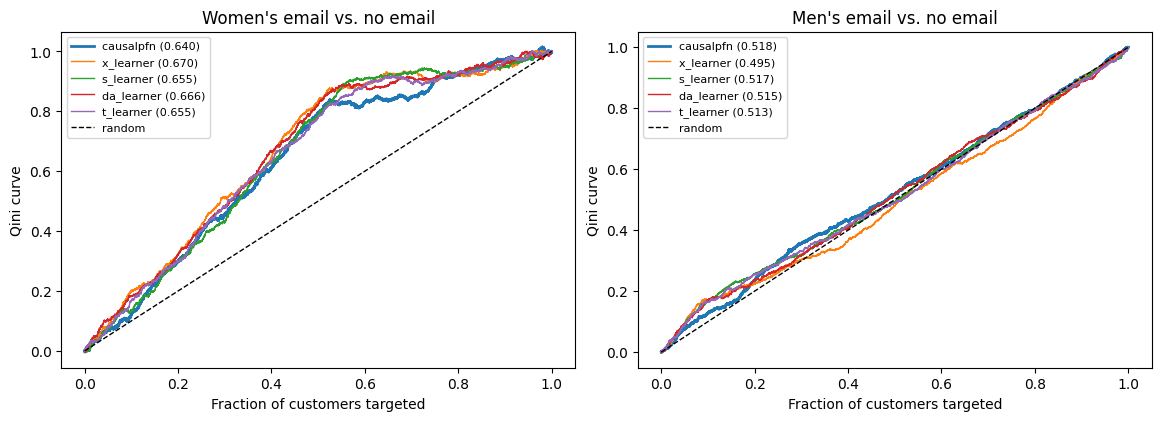

In [8]:
import matplotlib.pyplot as plt

from eval.qini import get_qini_curve

fig, axes = plt.subplots(1, len(TASKS_HERE), figsize=(11.5, 4.1), layout="constrained")
for ax, task in zip(axes, TASKS_HERE, strict=True):
    for method in benchmark.METHODS:
        df = predictions[task][method]
        curve, score = get_qini_curve(
            df["t"].to_numpy(float), df["y"].to_numpy(float), df["uplift_pred"].to_numpy(float)
        )
        fraction = np.arange(1, len(curve) + 1) / len(curve)
        ax.plot(fraction, curve, label=f"{method} ({score:.3f})", lw=2 if method == "causalpfn" else 1)
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="random")
    ax.set_title(ARM_LABELS[task])
    ax.set_xlabel("Fraction of customers targeted")
    ax.set_ylabel("Qini curve")
    ax.legend(fontsize=8)
fig.savefig(REPORTS / "qini_hillstrom.png", dpi=150)
plt.show()